# Final Project Demo Day: Wildfire Classification

## End-to-end walkthrough — from dataset audit to held-out evaluation

This is a **new final-project notebook**, not a copy of the earlier exploratory-analysis notebook. It explains the complete final workflow: label-coverage decisions, descriptive plots, leakage-aware feature engineering, chronological validation, model selection, final test results, and limitations.

> **Project question:** Can daily weather indicators classify a day on which a wildfire start was recorded?
>
> **Scope warning:** The predictors include weather measured on the target date. This is retrospective same-day classification, not a validated early-warning system.

**Dataset record:** [California Weather and Fire Prediction Dataset (1984–2025)](https://doi.org/10.5281/zenodo.14712845), CC BY 4.0. The dataset record describes weather sourced from NOAA Climate Data Online and wildfire incidents from CAL FIRE.

## Notebook map
1. Load the project data
2. Audit label coverage and missingness
3. Explore season, year, and temperature patterns
4. Build past-only features and a chronological split
5. Run time-series model comparison
6. Evaluate the final holdout
7. Interpret diagnostics and limitations

## 1. Load the project data
The project-root discovery makes the notebook runnable from either the project folder or `notebooks/`. The raw file is used to audit the label-coverage decision; the 1984–2023 analysis file is used for the primary analysis.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

CANDIDATES = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in CANDIDATES if (p / "run_milestone4.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

RAW_PATH = ROOT / "data" / "raw" / "CA_Weather_Fire_Dataset_1984-2025.csv"
DATA_PATH = ROOT / "data" / "processed" / "california_wildfire_1984_2023.csv"
raw = pd.read_csv(RAW_PATH, parse_dates=["DATE"]).sort_values("DATE").reset_index(drop=True)
df = pd.read_csv(DATA_PATH, parse_dates=["DATE"]).sort_values("DATE").reset_index(drop=True)

sns.set_theme(style="whitegrid", context="notebook")
print(f"Source rows: {len(raw):,}")
print(f"Analysis rows: {len(df):,}")
print(f"Analysis period: {df['DATE'].min().date()} to {df['DATE'].max().date()}")

Source rows: 14,988
Analysis rows: 14,610
Analysis period: 1984-01-01 to 2023-12-31


## 2. Audit coverage and missing values
The source contains 14,988 daily observations. We excluded 378 rows from 2024 and the first 12 days of 2025 because all available labels in that short period were negative. We treat this as a potential label-coverage gap, not proof that no fires occurred.

In [2]:
annual_label_rate = raw.groupby(raw["DATE"].dt.year)["FIRE_START_DAY"].mean()
audit = pd.DataFrame({
    "Metric": ["Source rows", "Analysis rows", "Excluded rows", "Duplicate rows", "Missing AVG_WIND_SPEED values"],
    "Value": [len(raw), len(df), len(raw) - len(df), int(raw.duplicated().sum()), int(df["AVG_WIND_SPEED"].isna().sum())]
})
display(audit)
print("Positive-label rate by final source years:")
display((annual_label_rate.tail(3) * 100).round(2).rename("Positive-label rate (%)"))

,Metric,Value
0,Source rows,14988
1,Analysis rows,14610
2,Excluded rows,378
3,Duplicate rows,0
4,Missing AVG_WIND_SPEED values,3


Positive-label rate by final source years:


DATE
2023    38.63
2024     0.00
2025     0.00
Name: Positive-label rate (%), dtype: float64

### Coverage and missingness visualization
The left panel shows missing observations within the analysis period. The right panel shows positive-label rate by source year; the all-negative tail motivates the cutoff and requires a coverage audit.

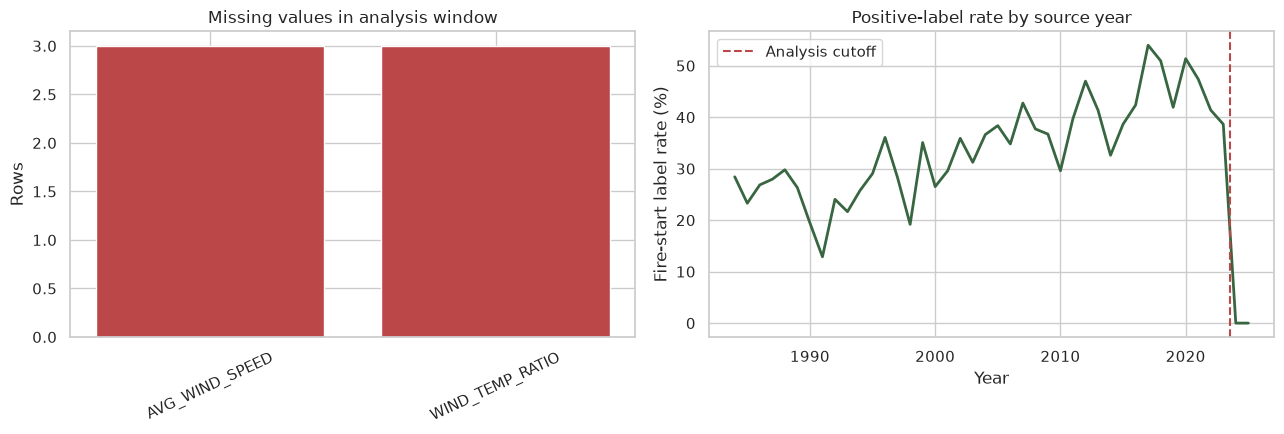

In [3]:
missing = df.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]
annual_rate_pct = annual_label_rate * 100
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
if len(missing):
    axes[0].bar(missing.index.astype(str), missing.values, color="#BC4749")
axes[0].set_title("Missing values in analysis window")
axes[0].set_ylabel("Rows")
axes[0].tick_params(axis="x", rotation=25)
axes[1].plot(annual_rate_pct.index, annual_rate_pct.values, color="#386641", linewidth=2)
axes[1].axvline(2023.5, color="#BC4749", linestyle="--", label="Analysis cutoff")
axes[1].set_title("Positive-label rate by source year")
axes[1].set_ylabel("Fire-start label rate (%)")
axes[1].set_xlabel("Year")
axes[1].legend()
fig.tight_layout()
plt.show()

## 3. Exploratory analysis: season and year
These plots summarize patterns in the observed dataset. They are descriptive and do not establish that season or time causes fire starts.

Recorded fire-start label rate by season (%):


SEASON
Winter     7.53
Spring    22.15
Summer    70.30
Fall      35.63
Name: Fire-start rate (%), dtype: float64

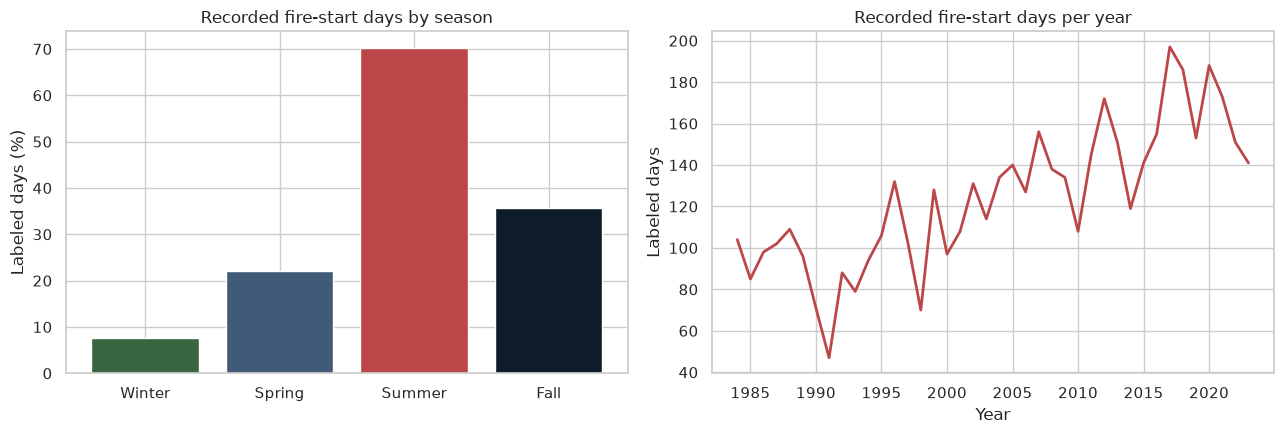

In [4]:
season_order = ["Winter", "Spring", "Summer", "Fall"]
season_rate = df.groupby("SEASON")["FIRE_START_DAY"].mean().reindex(season_order) * 100
yearly_count = df.groupby(df["DATE"].dt.year)["FIRE_START_DAY"].sum()
print("Recorded fire-start label rate by season (%):")
display(season_rate.round(2).rename("Fire-start rate (%)"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(season_rate.index, season_rate.values, color=["#386641", "#415A77", "#BC4749", "#0D1B2A"])
axes[0].set_title("Recorded fire-start days by season")
axes[0].set_ylabel("Labeled days (%)")
axes[1].plot(yearly_count.index, yearly_count.values, color="#BC4749", linewidth=2)
axes[1].set_title("Recorded fire-start days per year")
axes[1].set_ylabel("Labeled days")
axes[1].set_xlabel("Year")
fig.tight_layout()
plt.show()

### Temperature quartiles
Maximum temperature is divided into four approximately equal-sized groups with `qcut`, and the fire-start label rate is calculated for each group. This is an association in the study sample, not a causal effect or an operational risk probability.

Fire-start label rate by maximum-temperature quartile (%):


MAX_TEMP_QUARTILE
(49.999, 65.0]     7.20
(65.0, 70.0]      28.62
(70.0, 75.0]      48.06
(75.0, 106.0]     53.79
Name: Fire-start rate (%), dtype: float64

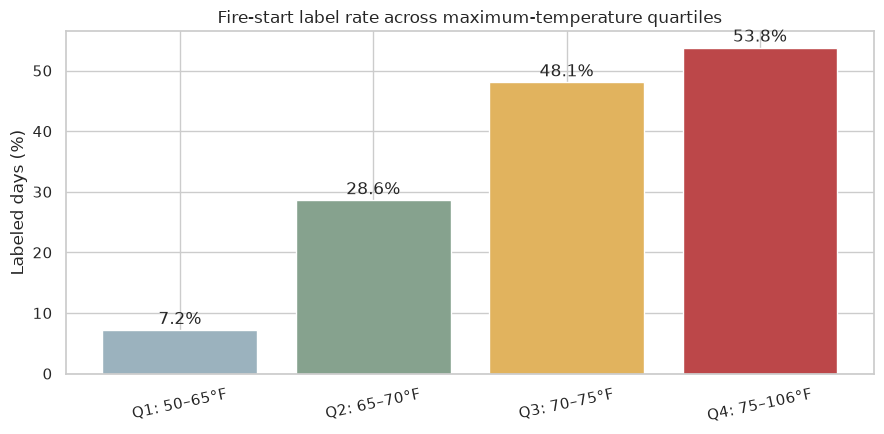

In [5]:
temp = df.dropna(subset=["MAX_TEMP"]).copy()
temp["MAX_TEMP_QUARTILE"] = pd.qcut(temp["MAX_TEMP"], 4, duplicates="drop")
temp_rate = temp.groupby("MAX_TEMP_QUARTILE", observed=True)["FIRE_START_DAY"].mean() * 100
print("Fire-start label rate by maximum-temperature quartile (%):")
display(temp_rate.round(2).rename("Fire-start rate (%)"))
fig, ax = plt.subplots(figsize=(9, 4.5))
labels = [f"Q{i + 1}: {interval.left:.0f}–{interval.right:.0f}°F" for i, interval in enumerate(temp_rate.index)]
ax.bar(labels, temp_rate.values, color=["#9BB2BE", "#86A28E", "#E1B35E", "#BC4749"])
ax.set_title("Fire-start label rate across maximum-temperature quartiles")
ax.set_ylabel("Labeled days (%)")
ax.tick_params(axis="x", rotation=12)
for i, value in enumerate(temp_rate.values):
    ax.text(i, value + 1, f"{value:.1f}%", ha="center")
fig.tight_layout()
plt.show()

## 4. Past-only features and chronological split
We rebuild the preceding-seven-day weather summaries with `shift(1)`, preventing the target day from entering a feature intended to represent prior conditions. The first 80% of observations are used for training and the final 20% are held out for testing. A chronological split better reflects evaluation on a later period than a random split.

In [6]:
df_model = df.sort_values("DATE").reset_index(drop=True).copy()
df_model["PREVIOUS_7D_PRECIPITATION"] = (
    df_model["PRECIPITATION"].shift(1).rolling(7, min_periods=1).sum()
)
df_model["PREVIOUS_7D_AVG_WIND_SPEED"] = (
    df_model["AVG_WIND_SPEED"].shift(1).rolling(7, min_periods=1).mean()
)
cut = int(len(df_model) * 0.80)
train = df_model.iloc[:cut].copy()
test = df_model.iloc[cut:].copy()
print(f"Training: {len(train):,} days | {train.DATE.min().date()} to {train.DATE.max().date()}")
print(f"Test: {len(test):,} days | {test.DATE.min().date()} to {test.DATE.max().date()}")
print(f"Positive-label rate — training: {train.FIRE_START_DAY.mean():.1%}")
print(f"Positive-label rate — test: {test.FIRE_START_DAY.mean():.1%}")

Training: 11,688 days | 1984-01-01 to 2015-12-31
Test: 2,922 days | 2016-01-01 to 2023-12-31
Positive-label rate — training: 31.0%
Positive-label rate — test: 46.0%


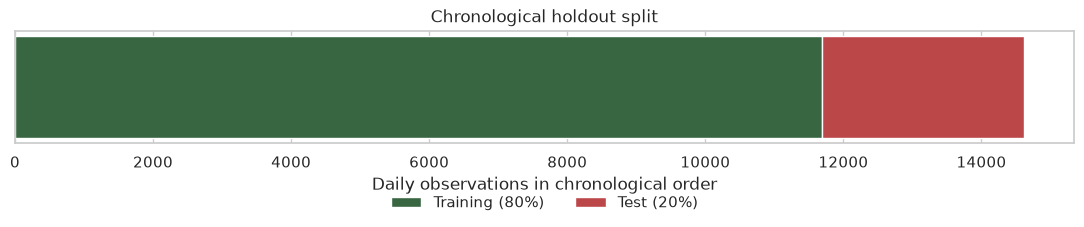

In [7]:
fig, ax = plt.subplots(figsize=(11, 2.8))
ax.barh([0], [len(train)], color="#386641", height=0.42, label="Training (80%)")
ax.barh([0], [len(test)], left=[len(train)], color="#BC4749", height=0.42, label="Test (20%)")
ax.set_yticks([])
ax.set_xlabel("Daily observations in chronological order")
ax.set_title("Chronological holdout split")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.35), ncol=2, frameon=False)
fig.tight_layout()
plt.show()

## 5. Preprocessing pipeline and model comparison
Numeric fields are median-imputed and standardized. `SEASON` is imputed with the most frequent category and one-hot encoded. These transformations are inside each model pipeline so they are fitted using only the training portion of each validation fold. Four candidates are compared with five expanding time-series folds; the selection rule uses mean Average Precision.

In [8]:
from run_milestone4 import make_preprocessor, make_models
from sklearn.model_selection import TimeSeriesSplit

print("Numeric preprocessing: median imputation → StandardScaler")
print("Season preprocessing: most-frequent imputation → One-Hot Encoding")
print("Candidate models:")
for name in make_models():
    print("-", name)
print("Time-series validation folds:", TimeSeriesSplit(n_splits=5).n_splits)

Numeric preprocessing: median imputation → StandardScaler
Season preprocessing: most-frequent imputation → One-Hot Encoding
Candidate models:
- Majority baseline
- Logistic Regression
- Random Forest
- Histogram Gradient Boosting
Time-series validation folds: 5


### Run the recorded modeling pipeline
The next cell calls the actual project implementation in `run_milestone4.py`. It regenerates the CV reports, final holdout metrics, predictions, and diagnostic plots; the model logic is not copied into a second implementation here.

In [9]:
from run_milestone4 import run
summary = run()

{
  "selected_model": "Logistic Regression",
  "selection_cv_average_precision": 0.6516965386925063,
  "selection_cv_average_precision_std": 0.1021246247665375,
  "test_metrics": {
    "accuracy": 0.7166324435318275,
    "balanced_accuracy": 0.727988355513308,
    "precision": 0.641602634467618,
    "recall": 0.8697916666666666,
    "f1": 0.7384712571067593,
    "roc_auc": 0.8386520007242441,
    "average_precision": 0.7973229702862599
  },
  "train_positive_rate": 0.3103182751540041,
  "test_positive_rate": 0.459958932238193,
  "confusion_matrix": [
    [
      925,
      653
    ],
    [
      175,
      1169
    ]
  ],
  "top_features": [
    {
      "feature": "SEASON",
      "importance_mean": 0.11328204151698082,
      "importance_std": 0.01045144476207729
    },
    {
      "feature": "AVG_WIND_SPEED",
      "importance_mean": 0.09372097253770466,
      "importance_std": 0.008432230135288685
    },
    {
      "feature": "WIND_TEMP_RATIO",
      "importance_mean": 0.067361226820

### Compare cross-validation results
Logistic Regression has a slightly higher mean Average Precision than Random Forest, but the gap is small relative to fold-to-fold variation. The model is selected by the predeclared rule, not described as a decisive winner.

,model,cv_average_precision_mean,cv_average_precision_std,cv_balanced_accuracy_mean,cv_f1_mean
0,Logistic Regression,0.652,0.102,0.742,0.646
1,Random Forest,0.648,0.113,0.755,0.660
2,Histogram Gradient Boosting,0.623,0.126,0.698,0.577
3,Majority baseline,0.321,0.071,0.500,0.000


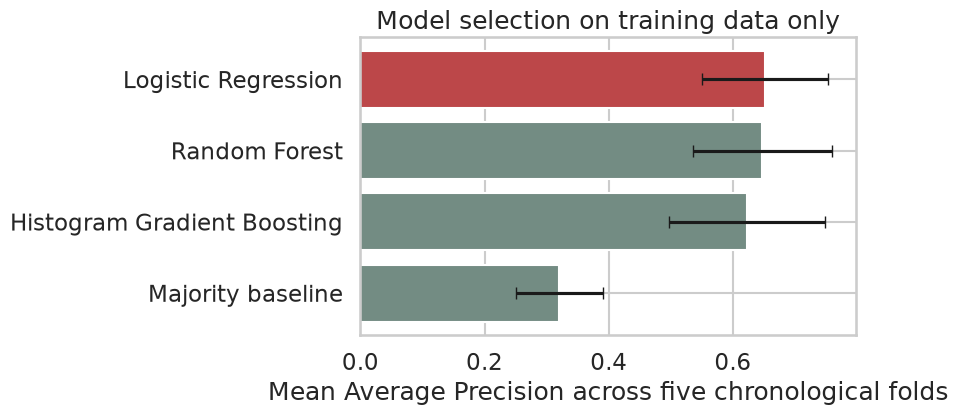

In [10]:
comparison = pd.read_csv(ROOT / "reports" / "model_comparison_cv.csv")
comparison = comparison.sort_values("cv_average_precision_mean", ascending=False)
display(comparison[["model", "cv_average_precision_mean", "cv_average_precision_std", "cv_balanced_accuracy_mean", "cv_f1_mean"]].round(3))

fig, ax = plt.subplots(figsize=(9, 4.5))
plot_data = comparison.sort_values("cv_average_precision_mean")
colors = ["#BC4749" if name == "Logistic Regression" else "#738C83" for name in plot_data["model"]]
ax.barh(plot_data["model"], plot_data["cv_average_precision_mean"],
        xerr=plot_data["cv_average_precision_std"], capsize=4, color=colors)
ax.set_xlabel("Mean Average Precision across five chronological folds")
ax.set_title("Model selection on training data only")
ax.set_xlim(left=0)
fig.tight_layout()
plt.show()

## 6. Final holdout evaluation
After selecting the candidate from training-period CV, the model is evaluated once on the later 2016–2023 holdout at a prespecified cutoff of 0.5. Recall is useful but does not tell the whole story, so the confusion matrix is reviewed alongside the metrics.

In [11]:
metrics = json.loads((ROOT / "reports" / "final_model_metrics.json").read_text(encoding="utf-8"))
print("Selected model:", metrics["selected_model"])
display(pd.Series(metrics["test_metrics"], name="Test score").round(3))
cm = np.array(metrics["confusion_matrix_labels_0_1"])
print("Rows: observed [no fire, fire]; columns: predicted [no fire, fire]")
display(pd.DataFrame(cm, index=["Observed: no fire", "Observed: fire"], columns=["Predicted: no fire", "Predicted: fire"]))

Selected model: Logistic Regression


accuracy             0.717
balanced_accuracy    0.728
precision            0.642
recall               0.870
f1                   0.738
roc_auc              0.839
average_precision    0.797
Name: Test score, dtype: float64

Rows: observed [no fire, fire]; columns: predicted [no fire, fire]


,Predicted: no fire,Predicted: fire
Observed: no fire,925,653
Observed: fire,175,1169


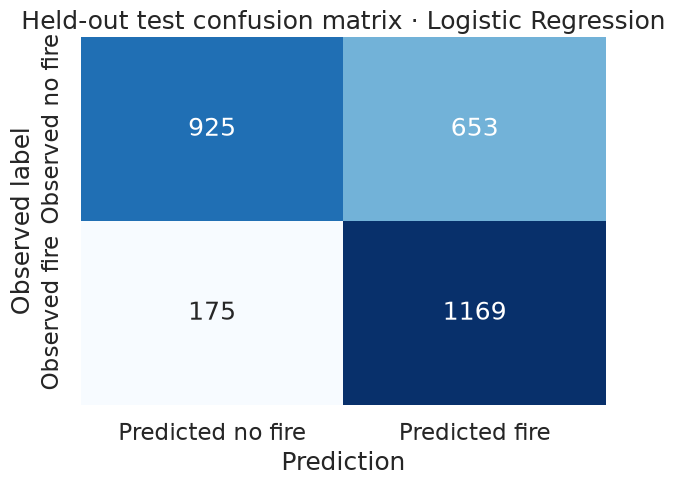

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 5.2))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Predicted no fire", "Predicted fire"],
            yticklabels=["Observed no fire", "Observed fire"], ax=ax)
ax.set_title("Held-out test confusion matrix · Logistic Regression")
ax.set_xlabel("Prediction")
ax.set_ylabel("Observed label")
fig.tight_layout()
plt.show()

### Interpret the errors
The test contains 2,922 days: 1,344 positive labels and 1,578 negative labels. The model identified 1,169 labeled fire-start days, missed 175, and produced 653 false alarms. A recall of 87.0% does not establish operational readiness; false-alarm cost, geography, and timing must be assessed separately.

## 7. Feature diagnostic and limitations
Permutation importance measures how Average Precision changes when a feature is shuffled on the held-out sample. It is an exploratory diagnostic of model reliance, not a causal effect.

,feature,importance_mean,importance_std
0,SEASON,0.1133,0.0105
1,AVG_WIND_SPEED,0.0937,0.0084
2,WIND_TEMP_RATIO,0.0674,0.0065
3,PREVIOUS_7D_PRECIPITATION,0.0245,0.0011
4,MIN_TEMP,0.0192,0.0041
5,MAX_TEMP,0.0108,0.0056
6,PRECIPITATION,0.0103,0.0015
7,TEMP_RANGE,0.0027,0.0007
8,DAY_OF_YEAR,0.0023,0.0005
9,MONTH,0.0003,0.0009


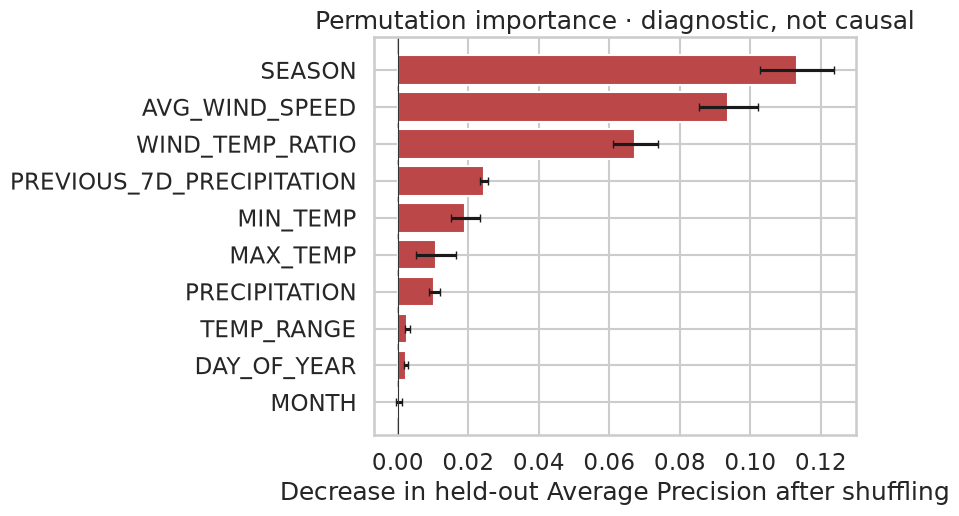

In [13]:
importance = pd.read_csv(ROOT / "reports" / "selected_model_permutation_importance.csv")
importance = importance.sort_values("importance_mean", ascending=False)
display(importance.head(10).round(4))
plot_importance = importance.head(10).sort_values("importance_mean")
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(plot_importance["feature"], plot_importance["importance_mean"],
        xerr=plot_importance["importance_std"], color="#BC4749", capsize=3)
ax.axvline(0, color="#333333", linewidth=0.8)
ax.set_xlabel("Decrease in held-out Average Precision after shuffling")
ax.set_title("Permutation importance · diagnostic, not causal")
fig.tight_layout()
plt.show()

## Final presentation summary

- We replaced a small pilot dataset with a substantially larger real dataset rather than synthetically enlarging it.
- The all-negative tail in 2024–2025 was treated as a possible label-coverage gap.
- The workflow uses a chronological holdout, past-only rolling features, and training-fold-only preprocessing.
- Logistic Regression was selected using the highest mean AP across five time-series folds; its advantage over Random Forest is small.
- Holdout fire recall is 87.0%, with 653 false alarms at the default 0.5 threshold.
- This is not a causal study or an early-warning system. Future work needs pre-event inputs and independent validation.

### Likely committee questions

1. **Why use `shift(1)`?** To exclude the current day from features intended to summarize previous days.
2. **Why a chronological split?** To evaluate on a later period without mixing future observations into training.
3. **Why Average Precision?** It summarizes precision–recall ranking across thresholds; accuracy alone can hide the error trade-off.
4. **Why Logistic Regression?** It had the highest mean AP under the predeclared selection rule, though the difference from Random Forest is small.
5. **Is this an early-warning model?** No. Weather measured on the target day is among the inputs.
6. **What do 653 false alarms mean?** Days flagged as fire starts whose observed labels were negative.

### Re-running the notebook

Run `python run_milestone3.py` first if the processed analysis file is missing, then execute this notebook from top to bottom. The modeling cell calls `run_milestone4.py` and regenerates the reports and plots.